# RT-DETR R101 on AWS Inferentia2 (inf2.8xlarge), Neuron SDK 2.33

**Model:** [`PekingU/rtdetr_r101vd_coco_o365`](https://huggingface.co/PekingU/rtdetr_r101vd_coco_o365)
(76M parameters, real-time object detection, 80 COCO classes), FP32
**Hardware:** inf2.8xlarge (2 NeuronCores)
**Software:** Neuron SDK 2.33 DLAMI, PyTorch Native (`torch.compile(backend="neuron")`), torch 2.14, NKI 0.7.0

## What changed since the SDK 2.28 version of this notebook

The earlier version used `torch_neuronx.trace()` plus a custom NKI `grid_sample` kernel. On SDK 2.33:

- `torch_neuronx.trace()` is no longer in the DLAMI. This notebook uses **PyTorch Native**
  (`torch.compile(backend="neuron")`) instead.
- RT-DETR's deformable attention calls `F.grid_sample`. It now compiles on Neuron, but it is slow.
- A small **`torch.gather` rewrite** of bilinear `grid_sample` (about 30 lines of PyTorch) is now the
  fastest option. **The custom NKI kernel is no longer needed.** Under the new compiler it is slower than
  the plain-PyTorch rewrite, so this notebook keeps it only as a comparison (section 5).
- The SDK 2.28 notebook needed two monkey-patches to run NKI inside `trace()`. They are gone. The kernel now
  plugs in with `torch_neuronx.nki_op` + `wrap_nki`.

## Instance setup

Launch a **inf2.8xlarge** with the *Deep Learning AMI Neuron (Ubuntu 24.04) SDK 2.33.0* and run:

```bash
source /opt/aws_neuronx_venv_torch_neuronx_2_14_0/bin/activate
# keep the DLAMI venv untouched: install extras into a side directory
pip install --target ~/xpkgs transformers==5.24.1 pillow requests jupyter
rm -rf ~/xpkgs/numpy* ~/xpkgs/bin           # use the venv's numpy
export PYTHONPATH=~/xpkgs
python -m jupyter notebook   # (jupyter is importable from ~/xpkgs)
```

All Neuron work runs in **subprocesses** (one process per NeuronCore). A NeuronCore stays owned by a process
until that process exits, so keeping device work out of the notebook kernel lets every cell (and the
data-parallel runs) get the cores it needs.

## 1. Environment

In [1]:
import os, sys, json, subprocess, time
import torch, torch_neuronx, nki
import numpy as np
print("torch", torch.__version__, "| torch_neuronx", torch_neuronx.__version__, "| nki", nki.__version__)
print("python", sys.version.split()[0])
cc = subprocess.run([sys.executable, "-m", "pip", "show", "neuronx-cc"], capture_output=True, text=True).stdout
print([l for l in cc.splitlines() if l.startswith("Version")][0].replace("Version:", "neuronx-cc"))
print(subprocess.run(["neuron-ls"], capture_output=True, text=True).stdout)

On-device RNG not available - CPU RNG will be used


torch 2.14.0+cu130 | torch_neuronx 2.14.3.0.1+b1b6c66 | nki 0.7.0+37713544100.gfede04bb
python 3.12.3


neuronx-cc 2.28.7631.0+8f7b0cf5
instance-type: inf2.8xlarge
+--------+--------+----------+--------+--------------+----------+------+
| NEURON | NEURON |  NEURON  | NEURON |     PCI      |   CPU    | NUMA |
| DEVICE | CORES  | CORE IDS | MEMORY |     BDF      | AFFINITY | NODE |
+--------+--------+----------+--------+--------------+----------+------+
| 0      | 2      | 0-1      | 32 GB  | 0000:00:1f.0 | 0-31     | -1   |
+--------+--------+----------+--------+--------------+----------+------+



## 2. The `grid_sample` replacements

RT-DETR's `MultiScaleDeformableAttention` samples each feature level with
`F.grid_sample(mode="bilinear", padding_mode="zeros", align_corners=False)`. The file below provides three
interchangeable implementations of that call, selected with `patch_model(variant)`:

| Variant | What it is |
|---|---|
| `native` | the stock HF code, unchanged (`F.grid_sample`) |
| `gather` | bilinear sampling written with 4 `torch.gather` calls + weights (**recommended**) |
| `nki` | the custom NKI kernel from the SDK 2.28 notebook (indirect-DMA gather, 128 rows per DMA), ported to NKI 0.7.0 |

Changes made to the NKI kernel for NKI 0.7.0: the output buffer is `nl.shared_hbm` (was `nl.hbm`), and the
kernel is registered as a PyTorch op with `nki_op` + `wrap_nki` instead of being called inside `trace()`.

In [2]:
%%writefile grid_sample_variants.py
"""
RT-DETR deformable-attention grid_sample variants for SDK 2.33 (PyTorch Native).

Variants (selected with patch_model(variant)):
  native  - stock HF forward, F.grid_sample as-is
  gather  - torch.gather bilinear rewrite (the SDK 2.28 baseline)
  nki     - NKI DMA-gather kernel (vector_offset indirect DMA), via nki_op + wrap_nki

All three implement grid_sample(mode="bilinear", padding_mode="zeros", align_corners=False).
"""

import os

import torch
import torch.nn.functional as F

P_MAX = 128

try:
    import nki
    import nki.language as nl
    import nki.isa as nisa

    NKI_AVAILABLE = True
except ImportError:  # CPU-only environments
    NKI_AVAILABLE = False


# --------------------------------------------------------------------------------------
# NKI kernel (same algorithm as the SDK 2.28 notebook; the output buffer is nl.shared_hbm,
# which NKI 0.3+ requires for returned outputs)
# --------------------------------------------------------------------------------------
if NKI_AVAILABLE:

    @nki.jit
    def nki_bilinear_grid_sample_kernel(
        input_flat,  # (H*W, C) fp32
        idx_00, idx_01, idx_10, idx_11,  # (num_out_padded, 1) int32
        w_00, w_01, w_10, w_11,  # (num_out_padded, 1) fp32
    ):
        num_out = idx_00.shape[0]
        C = input_flat.shape[1]
        num_tiles = num_out // P_MAX

        output = nl.ndarray((num_out, C), dtype=input_flat.dtype, buffer=nl.shared_hbm)

        for tile_idx in nl.affine_range(num_tiles):
            ts = tile_idx * P_MAX

            i00 = nl.ndarray((P_MAX, 1), dtype=nl.uint32, buffer=nl.sbuf)
            i01 = nl.ndarray((P_MAX, 1), dtype=nl.uint32, buffer=nl.sbuf)
            i10 = nl.ndarray((P_MAX, 1), dtype=nl.uint32, buffer=nl.sbuf)
            i11 = nl.ndarray((P_MAX, 1), dtype=nl.uint32, buffer=nl.sbuf)
            nisa.dma_copy(dst=i00, src=idx_00[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=i01, src=idx_01[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=i10, src=idx_10[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=i11, src=idx_11[ts:ts + P_MAX, 0:1])

            v00 = nl.ndarray((P_MAX, C), dtype=nl.float32, buffer=nl.sbuf)
            v01 = nl.ndarray((P_MAX, C), dtype=nl.float32, buffer=nl.sbuf)
            v10 = nl.ndarray((P_MAX, C), dtype=nl.float32, buffer=nl.sbuf)
            v11 = nl.ndarray((P_MAX, C), dtype=nl.float32, buffer=nl.sbuf)
            nisa.dma_copy(dst=v00, src=input_flat.ap(
                [[C, P_MAX], [1, C]], offset=0, vector_offset=i00, indirect_dim=0))
            nisa.dma_copy(dst=v01, src=input_flat.ap(
                [[C, P_MAX], [1, C]], offset=0, vector_offset=i01, indirect_dim=0))
            nisa.dma_copy(dst=v10, src=input_flat.ap(
                [[C, P_MAX], [1, C]], offset=0, vector_offset=i10, indirect_dim=0))
            nisa.dma_copy(dst=v11, src=input_flat.ap(
                [[C, P_MAX], [1, C]], offset=0, vector_offset=i11, indirect_dim=0))

            a00 = nl.ndarray((P_MAX, 1), dtype=nl.float32, buffer=nl.sbuf)
            a01 = nl.ndarray((P_MAX, 1), dtype=nl.float32, buffer=nl.sbuf)
            a10 = nl.ndarray((P_MAX, 1), dtype=nl.float32, buffer=nl.sbuf)
            a11 = nl.ndarray((P_MAX, 1), dtype=nl.float32, buffer=nl.sbuf)
            nisa.dma_copy(dst=a00, src=w_00[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=a01, src=w_01[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=a10, src=w_10[ts:ts + P_MAX, 0:1])
            nisa.dma_copy(dst=a11, src=w_11[ts:ts + P_MAX, 0:1])

            # acc = v00*a00; acc = (v01*a01) + acc; ...  (per-partition scale, fused multiply-add)
            tmp = nl.ndarray((P_MAX, C), dtype=nl.float32, buffer=nl.sbuf)
            nisa.tensor_scalar(dst=tmp, data=v00, op0=nl.multiply, operand0=a00)
            nisa.scalar_tensor_tensor(dst=tmp, data=v01, op0=nl.multiply, operand0=a01, op1=nl.add, operand1=tmp)
            nisa.scalar_tensor_tensor(dst=tmp, data=v10, op0=nl.multiply, operand0=a10, op1=nl.add, operand1=tmp)
            nisa.scalar_tensor_tensor(dst=tmp, data=v11, op0=nl.multiply, operand0=a11, op1=nl.add, operand1=tmp)

            nisa.dma_copy(dst=output[ts:ts + P_MAX, 0:C], src=tmp)

        return output


# --------------------------------------------------------------------------------------
# Shared bilinear index / weight computation (zero padding baked into the weights)
# --------------------------------------------------------------------------------------
def bilinear_indices_weights(input_tensor, grid):
    N, C, H, W = input_tensor.shape
    gx, gy = grid[..., 0], grid[..., 1]
    px = ((gx + 1.0) * W - 1.0) / 2.0
    py = ((gy + 1.0) * H - 1.0) / 2.0
    x0f = px.floor()
    y0f = py.floor()
    wx1 = px - x0f
    wy1 = py - y0f
    wx0 = 1.0 - wx1
    wy0 = 1.0 - wy1
    # int32 throughout (int64 in compiled graphs is narrowed to 32 bits anyway)
    x0 = x0f.to(torch.int32)
    y0 = y0f.to(torch.int32)
    x1 = x0 + 1
    y1 = y0 + 1
    vx0 = ((x0 >= 0) & (x0 < W)).to(input_tensor.dtype)
    vy0 = ((y0 >= 0) & (y0 < H)).to(input_tensor.dtype)
    vx1 = ((x1 >= 0) & (x1 < W)).to(input_tensor.dtype)
    vy1 = ((y1 >= 0) & (y1 < H)).to(input_tensor.dtype)
    w00 = wx0 * wy0 * vx0 * vy0
    w01 = wx1 * wy0 * vx1 * vy0
    w10 = wx0 * wy1 * vx0 * vy1
    w11 = wx1 * wy1 * vx1 * vy1
    x0c = x0.clamp(0, W - 1)
    y0c = y0.clamp(0, H - 1)
    x1c = x1.clamp(0, W - 1)
    y1c = y1.clamp(0, H - 1)
    idx = [y0c * W + x0c, y0c * W + x1c, y1c * W + x0c, y1c * W + x1c]
    wts = [w00, w01, w10, w11]
    return idx, wts


def grid_sample_gather(input_tensor, grid):
    """torch.gather bilinear rewrite (SDK 2.28 baseline)."""
    N, C, H, W = input_tensor.shape
    Ho, Wo = grid.shape[1], grid.shape[2]
    idx, wts = bilinear_indices_weights(input_tensor, grid)
    flat = input_tensor.reshape(N, C, H * W)
    out = 0
    for i, w in zip(idx, wts):
        g = torch.gather(flat, 2, i.reshape(N, 1, -1).to(torch.int64).expand(-1, C, -1))
        out = out + g.reshape(N, C, Ho, Wo) * w.unsqueeze(1)
    return out


# --------------------------------------------------------------------------------------
# NKI op registration (PyTorch Native)
# --------------------------------------------------------------------------------------
_NKI_OP = None


def _get_nki_op():
    global _NKI_OP
    if _NKI_OP is not None:
        return _NKI_OP
    from torch_neuronx import nki_op, wrap_nki

    lnc = int(os.environ.get("NEURON_LOGICAL_NC_CONFIG", "2"))
    caller = wrap_nki(nki_bilinear_grid_sample_kernel)[lnc]

    @nki_op("rtdetr::bilinear_grid_sample", mutates_args={})
    def _op(
        input_flat: torch.Tensor,
        i00: torch.Tensor, i01: torch.Tensor, i10: torch.Tensor, i11: torch.Tensor,
        w00: torch.Tensor, w01: torch.Tensor, w10: torch.Tensor, w11: torch.Tensor,
    ) -> torch.Tensor:
        return caller(input_flat, i00, i01, i10, i11, w00, w01, w10, w11)

    _NKI_OP = _op
    return _NKI_OP


def grid_sample_nki(input_tensor, grid):
    """NKI grid_sample: one kernel call for all N=(batch*heads) slices (indices pre-offset by b*H*W)."""
    op = _get_nki_op()
    N, C, H, W = input_tensor.shape
    Ho, Wo = grid.shape[1], grid.shape[2]
    num_out = Ho * Wo
    pad = (P_MAX - num_out % P_MAX) % P_MAX
    idx, wts = bilinear_indices_weights(input_tensor, grid)
    off = (torch.arange(N, dtype=torch.int32, device=input_tensor.device) * (H * W)).unsqueeze(1)
    idx = [F.pad(i.reshape(N, num_out) + off, (0, pad)).reshape(-1, 1) for i in idx]
    wts = [F.pad(w.reshape(N, num_out), (0, pad)).reshape(-1, 1) for w in wts]
    flat = input_tensor.reshape(N, C, H * W).permute(0, 2, 1).reshape(N * H * W, C).contiguous()
    o = op(flat, idx[0], idx[1], idx[2], idx[3], wts[0], wts[1], wts[2], wts[3])
    o = o.reshape(N, num_out + pad, C)[:, :num_out]
    return o.permute(0, 2, 1).reshape(N, C, Ho, Wo)


# --------------------------------------------------------------------------------------
# Model patch
# --------------------------------------------------------------------------------------
def _make_forward(gs_fn):
    def forward(self, value, value_spatial_shapes, value_spatial_shapes_list,
                level_start_index, sampling_locations, attention_weights, im2col_step=64):
        bs, _, nh, hd = value.shape
        _, nq, nh, nlv, npt, _ = sampling_locations.shape
        vl = value.split([h * w for h, w in value_spatial_shapes_list], dim=1)
        sg = 2 * sampling_locations - 1
        svl = []
        for lid, (h, w) in enumerate(value_spatial_shapes_list):
            v = vl[lid].flatten(2).transpose(1, 2).reshape(bs * nh, hd, h, w)
            g = sg[:, :, :, lid].transpose(1, 2).flatten(0, 1)
            svl.append(gs_fn(v, g))
        aw = attention_weights.transpose(1, 2).reshape(bs * nh, 1, nq, nlv * npt)
        out = (torch.stack(svl, dim=-2).flatten(-2) * aw).sum(-1).view(bs, nh * hd, nq)
        return out.transpose(1, 2).contiguous()

    return forward


def patch_model(variant):
    from transformers.models.rt_detr import modeling_rt_detr

    cls = modeling_rt_detr.MultiScaleDeformableAttention
    if variant == "native":
        return
    fn = {"gather": grid_sample_gather, "nki": grid_sample_nki}[variant]
    cls.forward = _make_forward(fn)

Overwriting grid_sample_variants.py


In [3]:
%%writefile rtdetr_neuron.py
"""RT-DETR R101 on Neuron (PyTorch Native, torch.compile). One process = one NeuronCore.

  python rtdetr_neuron.py --variant gather --bs 1 [--check] [--detect IMG] [--iters 100]

Prints one JSON line prefixed with RESULT: (latency, throughput, accuracy).
"""
import argparse, json, os, sys, time
import numpy as np
import torch
import torch._dynamo
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import grid_sample_variants as gsv

MODEL_ID = os.environ.get("RTDETR_MODEL", "PekingU/rtdetr_r101vd_coco_o365")


class Wrapper(torch.nn.Module):
    def __init__(self, m):
        super().__init__()
        self.model = m

    def forward(self, x):
        o = self.model(pixel_values=x)
        return o.logits, o.pred_boxes


def cos(a, b):
    return torch.nn.functional.cosine_similarity(
        a.flatten().double().unsqueeze(0), b.flatten().double().unsqueeze(0)).item()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--variant", default="gather", choices=["native", "gather", "nki"])
    ap.add_argument("--bs", type=int, default=1)
    ap.add_argument("--iters", type=int, default=100)
    ap.add_argument("--warmup", type=int, default=10)
    ap.add_argument("--check", action="store_true", help="accuracy vs cpu_ref.pt")
    ap.add_argument("--detect", default=None, help="pixel_values .pt file to run detection on")
    args = ap.parse_args()

    from transformers import RTDetrForObjectDetection
    model = RTDetrForObjectDetection.from_pretrained(MODEL_ID).eval()
    gsv.patch_model(args.variant)
    if args.variant == "nki":
        gsv._get_nki_op()  # register the custom op before Dynamo traces the model
    dev = torch.device("neuron")
    w = Wrapper(model).eval().to(dev)
    torch._dynamo.config.cache_size_limit = 64
    cw = torch.compile(w, backend="neuron", fullgraph=True, dynamic=False)

    res = {"variant": args.variant, "bs": args.bs, "rank": int(os.environ.get("RANK", "0"))}
    x = torch.randn(args.bs, 3, 640, 640).to(dev)
    with torch.no_grad():
        cw(x)[0].cpu()  # first call compiles (or loads the cached NEFF)

    if args.check:
        ref = torch.load("cpu_ref.pt")
        lc, bc = [], []
        with torch.no_grad():
            for i, xi in enumerate(ref["x"]):
                lo, bo = cw(xi.expand(args.bs, -1, -1, -1).contiguous().to(dev))
                lc.append(cos(ref["logits"][i], lo[:1].cpu()))
                bc.append(cos(ref["boxes"][i], bo[:1].cpu()))
        res.update(logits_cos_mean=float(np.mean(lc)), logits_cos_min=float(np.min(lc)),
                   boxes_cos_mean=float(np.mean(bc)), boxes_cos_min=float(np.min(bc)))

    if args.detect:
        pv = torch.load(args.detect).expand(args.bs, -1, -1, -1).contiguous()
        with torch.no_grad():
            lo, bo = cw(pv.to(dev))
        torch.save({"logits": lo[:1].cpu(), "boxes": bo[:1].cpu()}, args.detect + ".out")

    # DP barrier: every rank compiles first, then all ranks time together
    ws, bdir = int(os.environ.get("WORLD_SIZE", "1")), os.environ.get("DP_BARRIER_DIR")
    if ws > 1 and bdir:
        open(os.path.join(bdir, f"ready_{res['rank']}"), "w").close()
        while len([f for f in os.listdir(bdir) if f.startswith("ready_")]) < ws:
            time.sleep(0.05)

    with torch.no_grad():
        for _ in range(args.warmup):
            cw(x)[0].cpu()
        ts = []
        t_start = time.perf_counter()
        for _ in range(args.iters):
            t = time.perf_counter()
            lo, bo = cw(x)
            lo.cpu(); bo.cpu()
            ts.append((time.perf_counter() - t) * 1000)
        wall = time.perf_counter() - t_start
    ts = np.array(ts)
    res.update(p50_ms=float(np.percentile(ts, 50)), p95_ms=float(np.percentile(ts, 95)),
               throughput=args.bs * args.iters / wall)
    print("RESULT:" + json.dumps(res), flush=True)


if __name__ == "__main__":
    main()

Overwriting rtdetr_neuron.py


## 3. CPU reference

Twenty random 640x640 inputs run through the **unmodified** HF model on CPU (FP32). Every Neuron variant is
compared against these outputs.

In [4]:
from transformers import RTDetrForObjectDetection, RTDetrImageProcessor
MODEL_ID = "PekingU/rtdetr_r101vd_coco_o365"
cpu_model = RTDetrForObjectDetection.from_pretrained(MODEL_ID).eval()
print(f"parameters: {sum(p.numel() for p in cpu_model.parameters()) / 1e6:.1f}M")

torch.manual_seed(42)
xs = [torch.randn(1, 3, 640, 640) for _ in range(20)]
with torch.no_grad():
    outs = [cpu_model(pixel_values=x) for x in xs]
torch.save({"x": xs, "logits": [o.logits for o in outs], "boxes": [o.pred_boxes for o in outs]}, "cpu_ref.pt")
print("saved cpu_ref.pt: logits", tuple(outs[0].logits.shape), "boxes", tuple(outs[0].pred_boxes.shape))

[transformers] `RTDetrImageProcessor` requires torchvision (not installed); falling back to `RTDetrImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `RTDetrImageProcessorPil` directly to silence this warning.


Loading weights:   0%|          | 0/1019 [00:00<?, ?it/s]

parameters: 76.6M


saved cpu_ref.pt: logits (1, 300, 80) boxes (1, 300, 4)


## 4. Compile and validate the recommended path (`gather`)

The helper compiles the whole model as **one graph** (`fullgraph=True`), checks accuracy on the 20 reference
inputs, and times 100 calls (each call includes copying both outputs back to the host). The first run compiles;
the NEFF is cached under `/tmp/neff_cache`, so later runs of the same configuration start quickly.

In [5]:
def run(variant="gather", bs=1, check=False, detect=None, iters=100, env=None, cores="0"):
    """Run rtdetr_neuron.py in a subprocess on the given NeuronCore(s); return its RESULT dict."""
    e = dict(os.environ, NEURON_RT_VISIBLE_CORES=cores, **(env or {}))
    cmd = [sys.executable, "rtdetr_neuron.py", "--variant", variant, "--bs", str(bs), "--iters", str(iters)]
    if check: cmd.append("--check")
    if detect: cmd += ["--detect", detect]
    p = subprocess.run(cmd, env=e, capture_output=True, text=True)
    lines = [l for l in p.stdout.splitlines() if l.startswith("RESULT:")]
    if p.returncode or not lines:
        import re
        err = re.findall(r"\[NCC_[A-Z0-9]+\][^\n]{0,160}|NRT:[^\n]{0,160}|\w+Error: [^\n]{0,160}", p.stderr)
        raise RuntimeError(f"{variant} bs={bs} failed (rc={p.returncode}): " + (err[0] if err else p.stderr[-1500:]))
    return json.loads(lines[-1][7:])

def show(r, label):
    acc = (f"  logits cos {r['logits_cos_mean']:.6f} (min {r['logits_cos_min']:.6f}), "
           f"boxes cos {r['boxes_cos_mean']:.6f} (min {r['boxes_cos_min']:.6f})") if "logits_cos_mean" in r else ""
    print(f"{label:<34} p50 {r['p50_ms']:7.1f} ms  p95 {r['p95_ms']:7.1f} ms  {r['throughput']:6.1f} img/s{acc}")

results = {}
results["gather_bs1"] = run("gather", 1, check=True)
show(results["gather_bs1"], "gather, BS=1, 1 core")

gather, BS=1, 1 core               p50    51.6 ms  p95    52.3 ms    19.3 img/s  logits cos 0.999988 (min 0.999887), boxes cos 0.999345 (min 0.993955)


### Detection demo

A real COCO image goes through the compiled model (`gather` variant), followed by standard RT-DETR
post-processing (sigmoid scores, top detections above 0.5).

In [6]:
from PIL import Image
import requests
processor = RTDetrImageProcessor.from_pretrained(MODEL_ID)
image = Image.open(requests.get("http://images.cocodataset.org/val2017/000000039769.jpg", stream=True).raw)
pv = processor(images=image, return_tensors="pt")["pixel_values"]
torch.save(pv, "demo_pixels.pt")
run("gather", 1, detect="demo_pixels.pt", iters=1)
out = torch.load("demo_pixels.pt.out")

class _O:  # minimal object for the HF post-processor
    def __init__(s, lo, bo): s.logits, s.pred_boxes = lo, bo
dets = processor.post_process_object_detection(_O(out["logits"], out["boxes"]), threshold=0.5,
                                               target_sizes=[image.size[::-1]])[0]
with torch.no_grad():
    cpu_out = cpu_model(pixel_values=pv)
cpu_dets = processor.post_process_object_detection(cpu_out, threshold=0.5, target_sizes=[image.size[::-1]])[0]
print(f"Neuron: {len(dets['scores'])} objects | CPU: {len(cpu_dets['scores'])} objects")
for s, l, b in zip(dets["scores"], dets["labels"], dets["boxes"]):
    print(f"  {cpu_model.config.id2label[l.item()]:<10} {s.item():.3f}  box {[round(v, 1) for v in b.tolist()]}")

Neuron: 5 objects | CPU: 5 objects
  cat        0.967  box [12.5, 54.7, 316.5, 472.9]
  cat        0.959  box [346.4, 24.7, 639.7, 372.7]
  sofa       0.944  box [-0.1, -1.0, 639.9, 478.8]
  remote     0.939  box [40.5, 73.6, 175.3, 117.5]
  remote     0.892  box [333.6, 77.0, 370.3, 187.6]


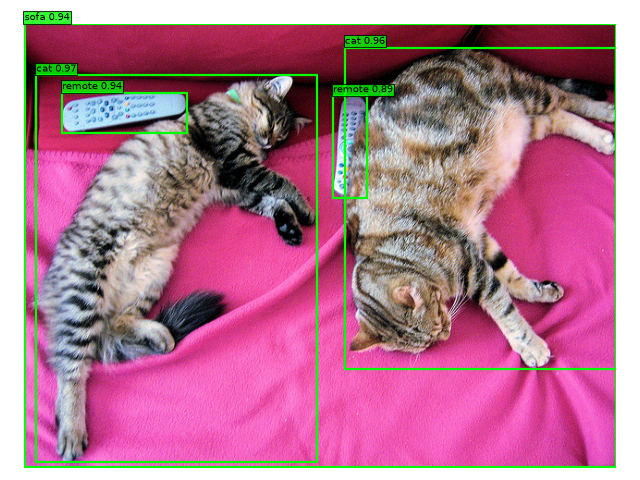

In [7]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt, matplotlib.patches as patches
fig, ax = plt.subplots(figsize=(8, 6)); ax.imshow(image); ax.axis("off")
for s, l, b in zip(dets["scores"], dets["labels"], dets["boxes"]):
    x0, y0, x1, y1 = b.tolist()
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="lime", linewidth=2))
    ax.text(x0, y0 - 4, f"{cpu_model.config.id2label[l.item()]} {s.item():.2f}", color="black",
            bbox=dict(facecolor="lime", alpha=0.8, pad=1), fontsize=9)
plt.tight_layout(); plt.savefig("detections.png", dpi=80); plt.close(fig)
from IPython.display import Image as IPImage, display
display(IPImage("detections.png"))

## 5. Is the NKI kernel still worth it? `native` vs `gather` vs `nki`

All three variants run on a single NeuronCore at BS=1. `native` is the unmodified model. On Inferentia2 it does **not** compile: the `F.grid_sample` lowering exceeds the compiler's instruction limit (`NCC_EBVF030`), so a replacement is required.

In [8]:
results["nki_bs1"] = run("nki", 1, check=True)
show(results["nki_bs1"], "nki kernel, BS=1, 1 core")
try:
    results["native_bs1"] = run("native", 1, check=True, iters=10)
    show(results["native_bs1"], "native F.grid_sample, BS=1, 1 core")
except RuntimeError as e:
    print("native F.grid_sample, BS=1:       does not compile ->", str(e).split(": ", 1)[1][:200])
show(results["gather_bs1"], "gather, BS=1, 1 core")
print(f"\ngather vs nki kernel: {results['nki_bs1']['p50_ms'] / results['gather_bs1']['p50_ms']:.2f}x faster")
if "native_bs1" in results:
    print(f"gather vs native:     {results['native_bs1']['p50_ms'] / results['gather_bs1']['p50_ms']:.1f}x faster")

nki kernel, BS=1, 1 core           p50    56.3 ms  p95    57.1 ms    17.7 img/s  logits cos 0.999988 (min 0.999887), boxes cos 0.999345 (min 0.993955)


native F.grid_sample, BS=1:       does not compile -> [NCC_EBVF030] Instructions generated by compiler 11218203 exceeds the typical limit of 5000000. Input computation graph is too big due to large operators - Consider using sm
gather, BS=1, 1 core               p50    51.6 ms  p95    52.3 ms    19.3 img/s  logits cos 0.999988 (min 0.999887), boxes cos 0.999345 (min 0.993955)

gather vs nki kernel: 1.09x faster


Every variant that compiles gives the same outputs to six digits. The plain-PyTorch `gather` rewrite is the fastest, so use it.
The NKI kernel's earlier advantage came from the SDK 2.28 XLA path, which lowered `torch.gather` poorly.

## 6. Full-device throughput (data parallel, one process per NeuronCore)

inf2.8xlarge has 2 NeuronCores. Each process loads its own copy of the model on one core and processes its own
batch. The total is the sum across processes, measured while both run together.

In [9]:
BIG_GRAPH = {"NEURON_CC_FLAGS": "--internal-hlo2tensorizer-options=--modular-flow-mac-target=1000000000000000"}

def run_dp(n, bs, env=None, variant="gather"):
    """Launch n ranks (one NeuronCore each), all timed together; return aggregate img/s."""
    import tempfile
    bdir = tempfile.mkdtemp()
    base = dict(os.environ, WORLD_SIZE=str(n), DP_BARRIER_DIR=bdir, OMP_NUM_THREADS="1", **(env or {}))
    procs = [subprocess.Popen([sys.executable, "rtdetr_neuron.py", "--variant", variant, "--bs", str(bs), "--iters", "100"],
                              env=dict(base, RANK=str(r), NEURON_RT_VISIBLE_CORES=str(r)),
                              stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True) for r in range(n)]
    outs = [p.communicate() for p in procs]
    rs = []
    for p, (o, e) in zip(procs, outs):
        lines = [l for l in o.splitlines() if l.startswith("RESULT:")]
        if p.returncode or not lines:
            print(e[-4000:]); raise RuntimeError("rank failed")
        rs.append(json.loads(lines[-1][7:]))
    tot = sum(r["throughput"] for r in rs)
    print(f"DP={n} BS={bs}/core {variant:<7} {tot:7.1f} img/s   p50 per rank {[round(r['p50_ms'], 1) for r in rs]} ms")
    return tot

dp = {}
dp["bs1"] = run_dp(2, 1)
dp["bs2"] = run_dp(2, 2, env=BIG_GRAPH)
dp["bs1_nki"] = run_dp(2, 1, variant="nki")

DP=2 BS=1/core gather     36.9 img/s   p50 per rank [53.6, 54.8] ms


DP=2 BS=2/core gather     20.6 img/s   p50 per rank [191.3, 196.8] ms


DP=2 BS=1/core nki        33.9 img/s   p50 per rank [58.6, 59.4] ms


## 7. Summary

In [10]:
print("RT-DETR R101, inf2.8xlarge, FP32, SDK 2.33 PyTorch Native")
print("=" * 64)
print(f"{'Configuration':<44}{'img/s':>10}")
print("-" * 64)
for k, label in [("bs1", "gather, 2 cores x BS=1"), ("bs2", "gather, 2 cores x BS=2"),
                 ("bs1_nki", "nki kernel, 2 cores x BS=1")]:
    print(f"{label:<44}{dp[k]:>10.1f}")
best = max((v, k) for k, v in dp.items())
print("-" * 64)
print(f"Best: {best[1]} at {best[0]:.1f} img/s per inf2.8xlarge")
print(f"Single core, BS=1, gather: {results['gather_bs1']['p50_ms']:.1f} ms p50")

RT-DETR R101, inf2.8xlarge, FP32, SDK 2.33 PyTorch Native
Configuration                                    img/s
----------------------------------------------------------------
gather, 2 cores x BS=1                            36.9
gather, 2 cores x BS=2                            20.6
nki kernel, 2 cores x BS=1                        33.9
----------------------------------------------------------------
Best: bs1 at 36.9 img/s per inf2.8xlarge
Single core, BS=1, gather: 51.6 ms p50


**Takeaways**

- On SDK 2.33, RT-DETR R101 runs on inf2.8xlarge through PyTorch Native with **no custom kernel**. Replace
  `F.grid_sample` with the 30-line `torch.gather` bilinear rewrite and compile the whole model with
  `torch.compile(backend="neuron", fullgraph=True)`.
- Accuracy matches the CPU FP32 reference (logits cosine about 0.99998).
- The NKI kernel from the SDK 2.28 notebook still works after a one-line port, but it is now slower than the
  plain-PyTorch rewrite. Keep it as an example of indirect-DMA gather in NKI, not as an optimization.
- For BS >= 2 on SDK 2.33, pass the `modular-flow-mac-target` compiler option shown in section 6 (fixed in a
  future SDK release).